<a href="https://colab.research.google.com/github/Joseherrera-G/colombia-energy-price-forecast/blob/main/energy_price_forecast.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

ENERGY PRICE FORECAST


##1. CONECT XM DATA


In [3]:
!pip install pydataxm -q

In [4]:
from pydataxm.pydataxm import ReadDB
import pandas as pd
import datetime as dt

api = ReadDB()
metricas = api.inventario_metricas
metricas[metricas["MetricId"].isin(["PrecBolsNaci", "DemaReal", "VoluUtilDiarEner", "PorcVoluUtilDiar"])]

,MetricId,MetricName,Entity,MaxDays,Type,Url,Filter,MetricUnits,MetricDescription
0,DemaReal,Demanda Real por Sistema,Sistema,31,HourlyEntities,https://servapibi.xm.com.co/hourly,No aplica,kWh,Demanda de usuarios regulados y no regulados q...
1,DemaReal,Demanda Real por Agente,Agente,31,HourlyEntities,https://servapibi.xm.com.co/hourly,Codigo Comercializador,kWh,Demanda de usuarios regulados y no regulados q...
6,PrecBolsNaci,Precio Bolsa Nacional por Sistema,Sistema,31,HourlyEntities,https://servapibi.xm.com.co/hourly,No aplica,COP/kWh,Precio de oferta de la última planta flexible ...
123,VoluUtilDiarEner,Volumen Útil diario Energía por Sistema,Sistema,31,DailyEntities,https://servapibi.xm.com.co/daily,No aplica,kWh,Volumen almacenado por encima del Nivel Minimo...
139,VoluUtilDiarEner,Volumen Útil diario Energía por Embalse,Embalse,31,DailyEntities,https://servapibi.xm.com.co/daily,Nombre Embalse,kWh,Volumen almacenado por encima del Nivel Minimo...
162,PorcVoluUtilDiar,Volumen Útil diario % por Sistema,Sistema,31,DailyEntities,https://servapibi.xm.com.co/daily,No aplica,%,Porcentaje de llenado del area util de un emba...
163,PorcVoluUtilDiar,Volumen Útil diario % por Embalse,Embalse,31,DailyEntities,https://servapibi.xm.com.co/daily,Nombre Embalse,%,Porcentaje de llenado del area util de un emba...


In [6]:
prueba = api.request_data("PrecBolsNaci", "Sistema", dt.date(2026, 9, 1), dt.date(2026, 9, 30))
print(prueba.columns.tolist())
prueba.head()

['Id', 'Values_code', 'Values_Hour01', 'Values_Hour02', 'Values_Hour03', 'Values_Hour04', 'Values_Hour05', 'Values_Hour06', 'Values_Hour07', 'Values_Hour08', 'Values_Hour09', 'Values_Hour10', 'Values_Hour11', 'Values_Hour12', 'Values_Hour13', 'Values_Hour14', 'Values_Hour15', 'Values_Hour16', 'Values_Hour17', 'Values_Hour18', 'Values_Hour19', 'Values_Hour20', 'Values_Hour21', 'Values_Hour22', 'Values_Hour23', 'Values_Hour24', 'Date']


,Id,Values_code,Values_Hour01,Values_Hour02,Values_Hour03,Values_Hour04,Values_Hour05,Values_Hour06,Values_Hour07,Values_Hour08,...,Values_Hour16,Values_Hour17,Values_Hour18,Values_Hour19,Values_Hour20,Values_Hour21,Values_Hour22,Values_Hour23,Values_Hour24,Date
0,Sistema,Sistema,959.96677,998.96677,997.96677,988.86477,997.96677,1009.96677,998.96677,949.96677,...,1014.96677,1019.96677,1019.96677,1059.96677,1059.96677,1059.96677,1059.96677,1019.96677,1014.96677,2026-09-01
1,Sistema,Sistema,1008.27729,1008.27729,1008.27729,998.27729,1008.27729,1008.27729,1008.27729,995.27729,...,1019.27729,1019.27729,1019.27729,1064.27929,1064.27929,1020.27729,1020.27729,1019.27729,1008.27729,2026-09-02
2,Sistema,Sistema,908.50262,909.98062,898.98062,898.98062,909.98062,909.98062,909.98062,898.98062,...,996.98062,1019.98062,1020.98062,1070.78062,1070.78062,1064.98262,1064.98262,1019.98062,969.98062,2026-09-03
3,Sistema,Sistema,899.19664,870.19664,870.19664,870.19664,870.19664,899.19664,899.19664,870.19664,...,917.19664,999.19664,1021.19664,1070.99664,1070.99664,1065.19864,1021.19664,999.19664,916.19664,2026-09-04
4,Sistema,Sistema,877.33162,877.33162,877.33162,877.33162,877.33162,877.33162,877.33162,602.33162,...,872.83162,877.33162,877.33162,1023.33162,1023.33162,900.33162,1067.33362,1023.33162,893.23662,2026-09-05


##2. CONVERT TO DAILY


In [8]:
import time

inicio = dt.date(2015, 1, 1)
fin = dt.date.today() - dt.timedelta(days=2)

partes = []
anios_fallidos = []

for anio in range(inicio.year, fin.year + 1):
    desde = dt.date(anio, 1, 1)
    hasta = min(dt.date(anio, 12, 31), fin)

    for intento in range(3):
        try:
            df = api.request_data("PrecBolsNaci", "Sistema", desde, hasta)
            partes.append(df)
            print(anio, "->", len(df), "días descargados")
            break
        except Exception as e:
            print(anio, "falló en el intento", intento + 1, ":", type(e).__name__)
            time.sleep(10)
    else:
        anios_fallidos.append(anio)

    time.sleep(3)

precio_raw = pd.concat(partes, ignore_index=True)
print("Tamaño final:", precio_raw.shape)
print("Años que fallaron:", anios_fallidos)
precio_raw.to_csv("precio_bolsa_raw.csv", index=False)

2015 -> 365 días descargados
2016 -> 366 días descargados
2017 -> 365 días descargados
2018 -> 365 días descargados
2019 -> 365 días descargados
2020 -> 366 días descargados
2021 -> 365 días descargados
2022 -> 365 días descargados
2023 -> 365 días descargados
2024 -> 366 días descargados
2025 -> 365 días descargados
2026 -> 287 días descargados
Tamaño final: (4305, 27)
Años que fallaron: []


In [9]:
columnas_horas = [c for c in precio_raw.columns if c.startswith("Values_Hour")]

precio = precio_raw[["Date"] + columnas_horas].copy()
precio["Date"] = pd.to_datetime(precio["Date"])
precio[columnas_horas] = precio[columnas_horas].apply(pd.to_numeric, errors="coerce")

precio["precio_promedio"] = precio[columnas_horas].mean(axis=1)
precio["precio_max"] = precio[columnas_horas].max(axis=1)

serie = precio.set_index("Date")[["precio_promedio", "precio_max"]].sort_index()
serie.tail()

,precio_promedio,precio_max
Date,,
2026-10-10,762.091777,1262.73536
2026-10-11,541.448322,632.03903
2026-10-12,521.047960,649.47346
2026-10-13,527.821478,690.37652
2026-10-14,528.953362,766.55032


In [10]:
print("Días:", len(serie))
print("Desde", serie.index.min().date(), "hasta", serie.index.max().date())
print("Fechas duplicadas:", serie.index.duplicated().sum())

dias_esperados = pd.date_range(serie.index.min(), serie.index.max(), freq="D")
print("Días faltantes:", len(dias_esperados.difference(serie.index)))

print("Valores vacíos:")
print(serie.isna().sum())

Días: 4305
Desde 2015-01-01 hasta 2026-10-14
Fechas duplicadas: 0
Días faltantes: 0
Valores vacíos:
precio_promedio    0
precio_max         0
dtype: int64


##3. EXPLORATORY ANALISIS

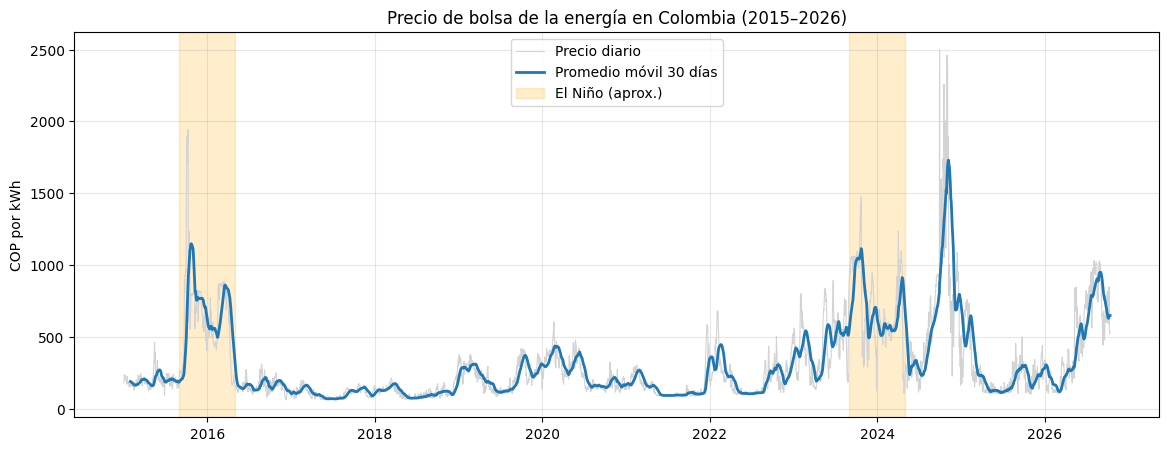

In [29]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(serie.index, serie["precio_promedio"], color="lightgray", linewidth=0.8, label="Precio diario")
ax.plot(serie.index, serie["precio_promedio"].rolling(30).mean(), color="tab:blue", linewidth=2, label="Promedio móvil 30 días")

ax.axvspan(pd.Timestamp("2015-09-01"), pd.Timestamp("2016-04-30"), color="orange", alpha=0.2, label="El Niño (aprox.)")
ax.axvspan(pd.Timestamp("2023-09-01"), pd.Timestamp("2024-04-30"), color="orange", alpha=0.2)

ax.set_title("Precio de bolsa de la energía en Colombia (2015–2026)")
ax.set_ylabel("COP por kWh")
ax.legend()
ax.grid(alpha=0.3)
plt.show()
fig.savefig("price_history.png", dpi=150, bbox_inches="tight")

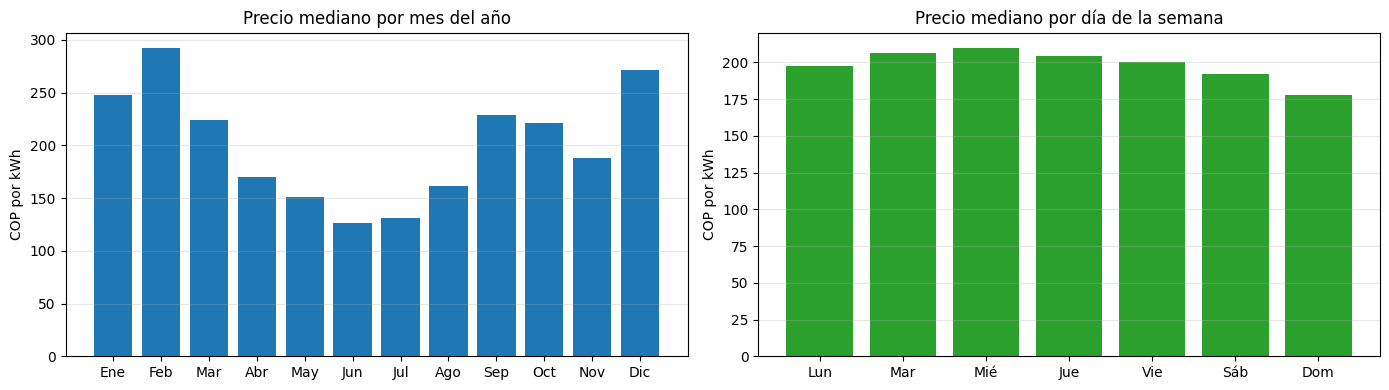

In [31]:
por_mes = serie["precio_promedio"].groupby(serie.index.month).median()
por_dia = serie["precio_promedio"].groupby(serie.index.dayofweek).median()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].bar(por_mes.index, por_mes.values, color="tab:blue")
axes[0].set_title("Precio mediano por mes del año")
axes[0].set_xticks(range(1, 13))
axes[0].set_xticklabels(["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"])

axes[1].bar(por_dia.index, por_dia.values, color="tab:green")
axes[1].set_title("Precio mediano por día de la semana")
axes[1].set_xticks(range(7))
axes[1].set_xticklabels(["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"])

for a in axes:
    a.set_ylabel("COP por kWh")
    a.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()
fig.savefig("seasonality.png", dpi=150, bbox_inches="tight")

## 4.  Forecast

In [19]:
datos = serie[["precio_promedio"]].copy()

datos["lag_1"] = datos["precio_promedio"].shift(1)
datos["lag_7"] = datos["precio_promedio"].shift(7)
datos["media_7"] = datos["precio_promedio"].shift(1).rolling(7).mean()
datos["media_30"] = datos["precio_promedio"].shift(1).rolling(30).mean()
datos["dia_semana"] = datos.index.dayofweek
datos["mes"] = datos.index.month

datos = datos.dropna()
datos.tail()

,precio_promedio,lag_1,lag_7,media_7,media_30,dia_semana,mes
Date,,,,,,,
2026-10-10,762.091777,847.969915,661.090947,681.134878,638.847375,5,10
2026-10-11,541.448322,762.091777,641.376383,695.563568,644.601125,6,10
2026-10-12,521.047960,541.448322,604.048862,681.288130,644.446641,0,10
2026-10-13,527.821478,521.047960,591.801428,669.430859,645.704865,1,10
2026-10-14,528.953362,527.821478,651.363267,660.290866,648.528416,2,10


In [20]:
corte = "2026-01-01"

train = datos[datos.index < corte]
test = datos[datos.index >= corte]

columnas_X = ["lag_1", "lag_7", "media_7", "media_30", "dia_semana", "mes"]

print("Entrenamiento:", train.index.min().date(), "a", train.index.max().date(), "->", len(train), "días")
print("Prueba:       ", test.index.min().date(), "a", test.index.max().date(), "->", len(test), "días")

Entrenamiento: 2015-01-31 a 2025-12-31 -> 3988 días
Prueba:        2026-01-01 a 2026-10-14 -> 287 días


In [21]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error

y_real = test["precio_promedio"]

pred_ayer = test["lag_1"]
pred_semana = test["lag_7"]

modelo = HistGradientBoostingRegressor(random_state=42)
modelo.fit(train[columnas_X], train["precio_promedio"])
pred_modelo = modelo.predict(test[columnas_X])

resultados = {
    "Igual que ayer": pred_ayer,
    "Igual que hace 7 días": pred_semana,
    "Modelo (gradient boosting)": pred_modelo,
}

for nombre, pred in resultados.items():
    mae = mean_absolute_error(y_real, pred)
    print(f"{nombre:28s} error promedio = {mae:6.1f} COP/kWh")

Igual que ayer               error promedio =   44.1 COP/kWh
Igual que hace 7 días        error promedio =  111.0 COP/kWh
Modelo (gradient boosting)   error promedio =   49.4 COP/kWh


In [22]:
from sklearn.linear_model import LinearRegression

lineal = LinearRegression()
lineal.fit(train[columnas_X], train["precio_promedio"])
pred_lineal = lineal.predict(test[columnas_X])

cambio_train = train["precio_promedio"] - train["lag_1"]
modelo_cambio = HistGradientBoostingRegressor(random_state=42)
modelo_cambio.fit(train[columnas_X], cambio_train)
pred_cambio = test["lag_1"] + modelo_cambio.predict(test[columnas_X])

resultados["Regresión lineal"] = pred_lineal
resultados["GB que predice el cambio"] = pred_cambio

mae_ayer = mean_absolute_error(y_real, pred_ayer)

for nombre, pred in resultados.items():
    mae = mean_absolute_error(y_real, pred)
    mejora = (1 - mae / mae_ayer) * 100
    print(f"{nombre:28s} error = {mae:6.1f}   vs. 'igual que ayer': {mejora:+6.1f}%")

Igual que ayer               error =   44.1   vs. 'igual que ayer':   +0.0%
Igual que hace 7 días        error =  111.0   vs. 'igual que ayer': -151.6%
Modelo (gradient boosting)   error =   49.4   vs. 'igual que ayer':  -11.9%
Regresión lineal             error =   43.2   vs. 'igual que ayer':   +2.1%
GB que predice el cambio     error =   46.3   vs. 'igual que ayer':   -4.9%


## 5. Results

In [23]:
coeficientes = pd.Series(lineal.coef_, index=columnas_X).round(3)
print("Intercepto:", round(lineal.intercept_, 1))
print(coeficientes)

Intercepto: 24.7
lag_1         0.827
lag_7        -0.082
media_7       0.207
media_30      0.027
dia_semana   -6.443
mes           0.099
dtype: float64


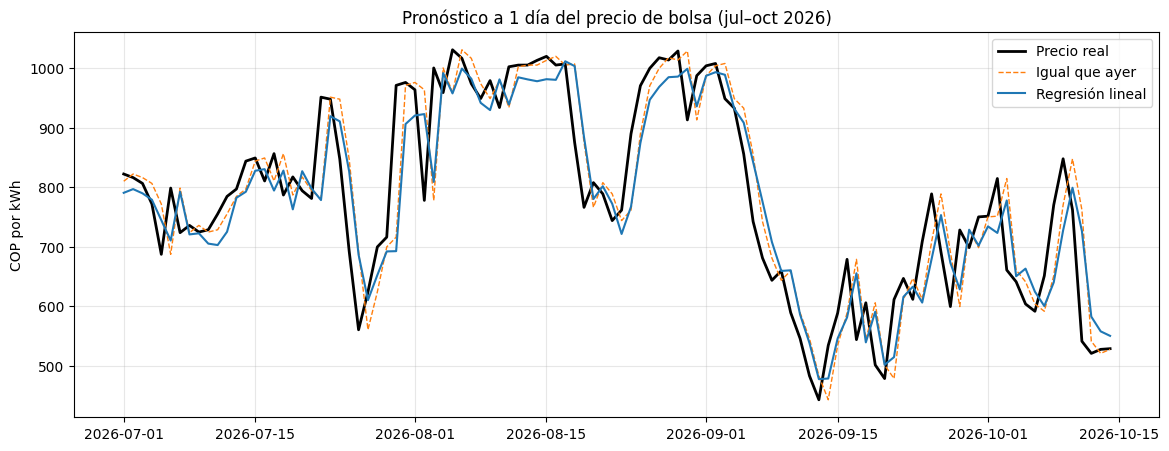

In [30]:
ultimos = y_real.index >= "2026-07-01"

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(y_real.index[ultimos], y_real[ultimos], color="black", linewidth=2, label="Precio real")
ax.plot(y_real.index[ultimos], pred_ayer[ultimos], color="tab:orange", linewidth=1, linestyle="--", label="Igual que ayer")
ax.plot(y_real.index[ultimos], pred_lineal[ultimos], color="tab:blue", linewidth=1.5, label="Regresión lineal")

ax.set_title("Pronóstico a 1 día del precio de bolsa (jul–oct 2026)")
ax.set_ylabel("COP por kWh")
ax.legend()
ax.grid(alpha=0.3)
plt.show()
fig.savefig("forecast_v1.png", dpi=150, bbox_inches="tight")

## 6.  Conclusions



- **Data:** 4,305 days of Colombian spot electricity prices (2015–2026), complete and with no gaps.
- **Patterns:** the biggest price spikes match El Niño droughts (2015–16, 2023–24). The highest spike (late 2024) happened after El Niño ended, which suggests that reservoir levels matter more than the El Niño label itself.
- **Seasonality:** prices are highest from December to March (dry season) and lowest in June–July, after the April–May rains refill the reservoirs. Weekends are cheaper because industrial demand drops.
- **Forecast (1 day ahead, test year 2026):** a linear regression beat the naive "same as yesterday" forecast by **2.1%**. Gradient boosting did worse than the naive forecast. With price history alone, there is little extra signal beyond yesterday's price.
- **Next step (v2):** add the drivers of price changes (reservoir levels, rainfall, El Niño index, demand), test longer horizons (7 and 30 days), and validate across several periods, not just one year.